# E3 – Clasificación: Riesgo de impago hipotecario
Modelo base vs. optimizado (`DecisionTreeClassifier`), `random_state = 29`.

In [5]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, recall_score,
                             precision_score, f1_score, fbeta_score, make_scorer)
RS = 29
TARGET = 'Riesgo_Impago'
COSTO_FN = 1_500_000   # crédito otorgado que termina en impago
COSTO_FP = 200_000     # cliente bueno rechazado (interés no ganado)
sns.set_theme(style='whitegrid')

## Fase 1 – Diagnóstico y calidad de datos (EDA)

In [6]:
url = 'https://raw.githubusercontent.com/TheDeliFeli/E2-IA/refs/heads/main/E3_IA/riesgo_crediticio.csv'
df = pd.read_csv(url, index_col=0)  # la 1ª columna es un índice exportado
print(df.shape); df.info()
display(df.describe().T)

(25000, 5)
<class 'pandas.core.frame.DataFrame'>
Index: 25000 entries, 0 to 24999
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Ingreso_Anual           25000 non-null  float64
 1   Monto_Prestamo          25000 non-null  float64
 2   Puntaje_Credito         25000 non-null  float64
 3   Relacion_Deuda_Ingreso  25000 non-null  float64
 4   Riesgo_Impago           25000 non-null  int64  
dtypes: float64(4), int64(1)
memory usage: 1.1 MB


,count,mean,std,min,25%,50%,75%,max
Ingreso_Anual,25000.0,55824.444883,29804.903177,7832.12,35051.3175,49234.685,68923.5200,348135.55
Monto_Prestamo,25000.0,220162.891849,60059.302633,50000.00,179438.0775,220241.470,261003.3625,451784.21
Puntaje_Credito,25000.0,680.033440,59.784266,457.00,640.0000,680.000,721.0000,850.00
Relacion_Deuda_Ingreso,25000.0,24.027319,13.615029,5.00,13.7875,21.450,31.3825,70.00
Riesgo_Impago,25000.0,0.071560,0.257763,0.00,0.0000,0.000,0.0000,1.00


In [7]:
print('Nulos por columna:\n', df.isna().sum())
print('Duplicados:', df.duplicated().sum())
# Inconsistencias lógicas
print('Ingreso <= 0 :', (df.Ingreso_Anual <= 0).sum())
print('Monto <= 0   :', (df.Monto_Prestamo <= 0).sum())
print('Puntaje fuera de [300, 850]:', (~df.Puntaje_Credito.between(300, 850)).sum())
print('DTI < 0 o > 100:', ((df.Relacion_Deuda_Ingreso < 0) | (df.Relacion_Deuda_Ingreso > 100)).sum())
print('DTI == 70 (posible tope/censura):', (df.Relacion_Deuda_Ingreso == 70).sum())
print('Puntaje == 850 (tope):', (df.Puntaje_Credito == 850).sum())
# Outliers (regla IQR)
for c in df.columns.drop(TARGET):
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    print(f'{c}: {n} outliers ({n/len(df):.1%})')

Nulos por columna:
 Ingreso_Anual             0
Monto_Prestamo            0
Puntaje_Credito           0
Relacion_Deuda_Ingreso    0
Riesgo_Impago             0
dtype: int64
Duplicados: 0
Ingreso <= 0 : 0
Monto <= 0   : 0
Puntaje fuera de [300, 850]: 0
DTI < 0 o > 100: 0
DTI == 70 (posible tope/censura): 196
Puntaje == 850 (tope): 49
Ingreso_Anual: 976 outliers (3.9%)
Monto_Prestamo: 157 outliers (0.6%)
Puntaje_Credito: 167 outliers (0.7%)
Relacion_Deuda_Ingreso: 663 outliers (2.7%)


Riesgo_Impago
0    23211
1     1789
Name: count, dtype: int64 
 Riesgo_Impago
0    0.9284
1    0.0716
Name: proportion, dtype: float64


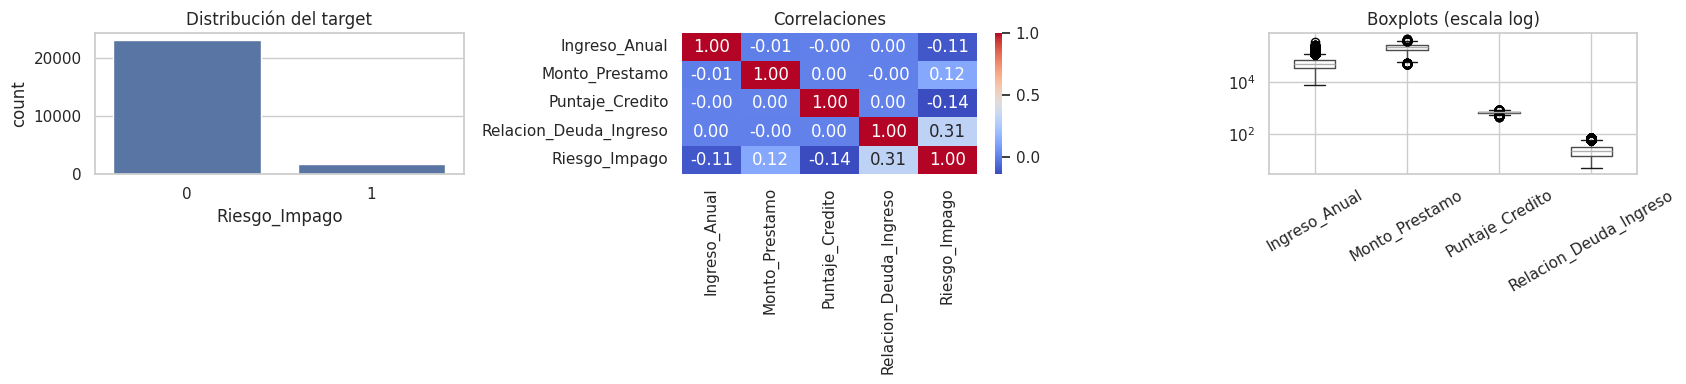

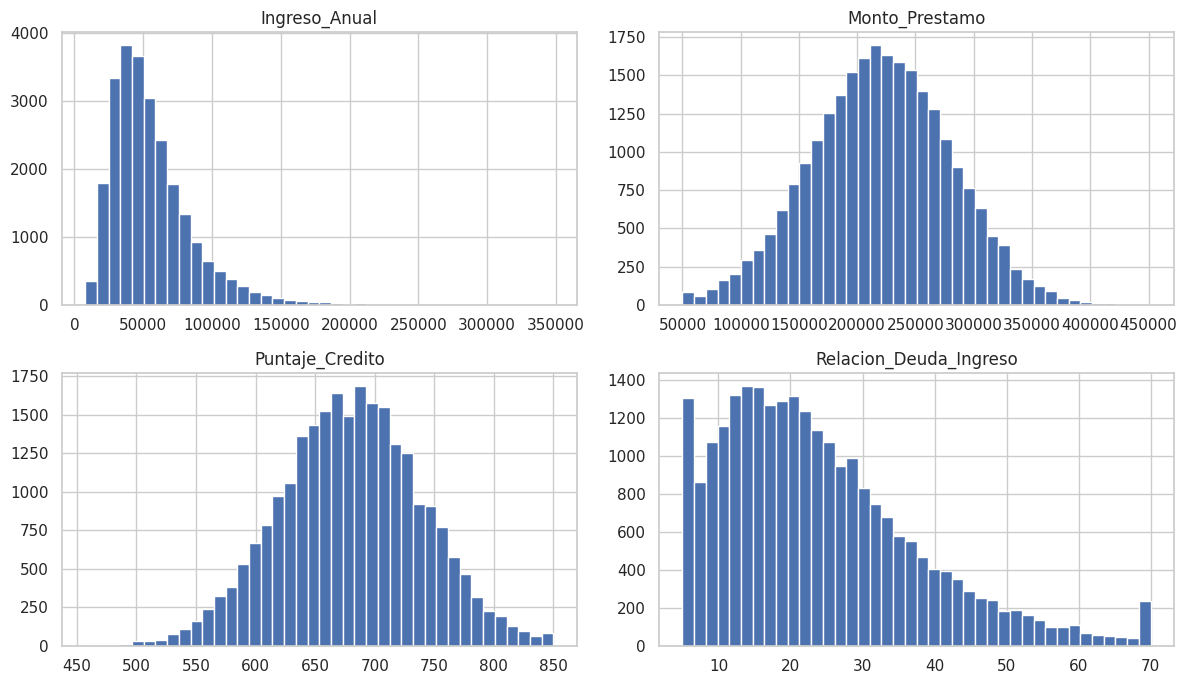

In [8]:
# Desbalance del target
vc = df[TARGET].value_counts(); print(vc, '\n', df[TARGET].value_counts(normalize=True).round(4))
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.countplot(x=TARGET, data=df, ax=ax[0]); ax[0].set_title('Distribución del target')
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax[1]); ax[1].set_title('Correlaciones')
df.drop(columns=TARGET).boxplot(ax=ax[2], rot=30); ax[2].set_yscale('log'); ax[2].set_title('Boxplots (escala log)')
plt.tight_layout(); plt.show()
df.drop(columns=TARGET).hist(bins=40, figsize=(12, 7)); plt.tight_layout(); plt.show()

**Hallazgos:** sin nulos ni duplicados; sin montos/ingresos ≤ 0; puntaje dentro de 300–850. Target fuertemente desbalanceado (~7,2 % de impagos), por lo que *accuracy* es engañosa. Ingreso y monto tienen cola derecha larga (outliers legítimos, no errores: se conservan; los árboles son robustos a ellos). DTI y puntaje presentan topes (70 y 850). La correlación más fuerte con el impago es DTI (+0,31).

## Fase 2 – Pipeline de limpieza y tratamiento

In [9]:
features = df.drop(columns=TARGET).columns.tolist()
preprocesador = ColumnTransformer([
    ('num', Pipeline([('imputar', SimpleImputer(strategy='median')),   # robusto a outliers
                      ('escalar', StandardScaler())]), features)])
# Las transformaciones se ajustan SOLO con train dentro del Pipeline -> sin data leakage.

## Fase 3 – Construcción del modelo

In [10]:
X, y = df[features], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RS)
print(y_train.mean().round(4), y_test.mean().round(4))   # misma tasa de impago en ambos

0.0716 0.0716


In [11]:
# Línea base: árbol por defecto
modelo_base = Pipeline([('pre', preprocesador), ('clf', DecisionTreeClassifier(random_state=RS))])
modelo_base.fit(X_train, y_train)

Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputar',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('escalar',
                                                                   StandardScaler())]),
                                                  ['Ingreso_Anual',
                                                   'Monto_Prestamo',
                                                   'Puntaje_Credito',
                                                   'Relacion_Deuda_Ingreso'])])),
                ('clf', DecisionTreeClassifier(random_state=29))])

In [ ]:
# Modelo optimizado: GridSearchCV con 5 hiperparámetros, CV estratificada
pipe = Pipeline([('pre', preprocesador), ('clf', DecisionTreeClassifier(random_state=RS))])
param_grid = {
    'clf__max_depth': [3, 5, 7, 10],
    'clf__min_samples_split': [2, 50],
    'clf__min_samples_leaf': [1, 25, 50],
    'clf__criterion': ['gini', 'entropy'],
    'clf__class_weight': [None, 'balanced', {0: 1, 1: 7.5}],  # 7.5 = razón de costos 1.5M/200k
}
# F2 pondera el recall el doble que la precisión, coherente con FN >> FP en costo
f2 = make_scorer(fbeta_score, beta=2)
gs = GridSearchCV(pipe, param_grid, scoring=f2, cv=StratifiedKFold(5, shuffle=True, random_state=RS), n_jobs=-1)
gs.fit(X_train, y_train)
modelo_opt = gs.best_estimator_
print('Mejores hiperparámetros:', gs.best_params_); print('F2 CV:', round(gs.best_score_, 4))

## Fase 4 – Evaluación sobre el conjunto de prueba
**Métricas elegidas:** *Recall* de la clase impago (mide cuántos morosos reales detectamos; cada FN cuesta $1,5 M) y *Precision* de la clase impago (controla cuántos buenos clientes rechazamos; cada FP cuesta $0,2 M). *Accuracy* se descarta: un modelo que aprueba a todos tendría ~93 % y 0 % de recall.

In [ ]:
filas, cms = [], {}
for nombre, m in [('Línea base', modelo_base), ('Optimizado', modelo_opt)]:
    p = m.predict(X_test); tn, fp, fn, tp = confusion_matrix(y_test, p).ravel(); cms[nombre] = confusion_matrix(y_test, p)
    filas.append({'Modelo': nombre, 'Recall (impago)': recall_score(y_test, p), 'Precision (impago)': precision_score(y_test, p),
                  'F1': f1_score(y_test, p), 'VN': tn, 'FP': fp, 'FN': fn, 'VP': tp,
                  'Costo total ($)': fn*COSTO_FN + fp*COSTO_FP,
                  'Recall train': recall_score(y_train, m.predict(X_train))})
res = pd.DataFrame(filas).set_index('Modelo'); display(res.round(3))
print('Referencia: aprobar a todos =', f'${y_test.sum()*COSTO_FN:,.0f}', '| rechazar a todos =', f'${(y_test==0).sum()*COSTO_FP:,.0f}')

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (n, cm) in zip(ax, cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=['Paga', 'Impago']).plot(ax=a, cmap='Blues', colorbar=False); a.set_title(n)
plt.tight_layout(); plt.show()

## Interpretación de la matriz de confusión (impacto financiero)

**Línea base (árbol sin restricciones).** Memoriza el entrenamiento (recall train = 1,00) y cae a recall ≈ 0,31 en prueba: detecta solo 112 de 358 morosos; 246 créditos malos se otorgan (FN) = $369 M, más 279 buenos clientes rechazados (FP) = $55,8 M. Costo total ≈ **$424,8 M**.

**Optimizado.** Detecta 218 de 358 morosos (recall ≈ 0,61), dejando pasar 140 (FN) = $210 M. A cambio rechaza 606 buenos clientes (FP) = $121,2 M. Costo total ≈ **$331,2 M**, un **22 % menos** que la base y 38 % menos que aprobar a todos ($537 M).

**Lectura de negocio.** Un FN es 7,5 veces más caro que un FP, por lo que conviene aceptar más FP (la precision baja a ≈ 0,26 y sube el rechazo de clientes viables) para capturar más impagos. Sigue habiendo ≈ 3 de cada 5 créditos rechazados que habrían sido pagados; esto es el costo de oportunidad aceptado.
